# 🦏 Peak-GCN — Single-Species (Elephant) Graph Convolutional Autoencoder
## One-Class Representation Learning & Real-Time Anomaly Detection (GCN version)

**Strategy:** Same as the GAT pipeline — isolate **only Elephant (Class 1)** samples and learn a **One-Class Graph Autoencoder**.
This version replaces the **Graph Attention (GAT)** encoder with a **Graph Convolutional Network (GCN)** encoder (`GCNConv`), which is simpler, faster, and has fewer parameters (no attention heads).

**How it works:**
- **Encoder (GCN):** Learns structural node embeddings of Elephant footstep sequences using spectral graph convolutions (each node aggregates neighbor features weighted by normalized graph structure, not learned attention).
- **Decoder:** Same MLP reconstructor as before — rebuilds the 8D footstep node features.
- **Anomaly Detection:** Trained only on normal Elephant footsteps → low reconstruction error for elephants, high error for anything else.

**Dataset:** `dset_allspec_150_chunks_clean.nc` — filtered strictly to **Class 1 (Elephant)**.


---
## 🔧 STEP 1: Setup & GPU Configuration
**What I'm doing:** Importing PyTorch, checking CUDA/GPU availability, auto-selecting the GPU with the most free VRAM (useful on multi-GPU machines), and fixing random seeds so results are reproducible.


In [2]:
import torch, os, numpy as np
print(f'PyTorch version : {torch.__version__}')
print(f'CUDA available  : {torch.cuda.is_available()}')

# Auto-select the GPU with the most free VRAM (if multiple GPUs are available)
if torch.cuda.is_available():
    num_gpus = torch.cuda.device_count()
    print(f'GPU count       : {num_gpus}')
    best_gpu_idx = 0
    max_free_mem = 0

    print('\nChecking VRAM availability across all GPUs:')
    for i in range(num_gpus):
        try:
            free_mem, total_mem = torch.cuda.mem_get_info(i)
            free_gb  = free_mem  / (1024**3)
            total_gb = total_mem / (1024**3)
            print(f'  GPU {i}: {torch.cuda.get_device_name(i):22s} | Free: {free_gb:5.1f} GB / {total_gb:5.1f} GB')
            if free_mem > max_free_mem:
                max_free_mem = free_mem
                best_gpu_idx = i
        except Exception as e:
            print(f'  GPU {i}: Could not query memory ({e})')

    device = torch.device(f'cuda:{best_gpu_idx}')
    torch.cuda.set_device(device)
    torch.cuda.empty_cache()
    print(f'\n🚀 Automatically selected GPU {best_gpu_idx} ({torch.cuda.get_device_name(best_gpu_idx)}) with {max_free_mem/(1024**3):.1f} GB free VRAM!')
else:
    device = torch.device('cpu')
    print('Using device    : cpu')

SEED = 42; torch.manual_seed(SEED); np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print('Setup complete ✓')


PyTorch version : 2.8.0+cu128
CUDA available  : True
GPU count       : 8

Checking VRAM availability across all GPUs:
  GPU 0: NVIDIA A100-SXM4-80GB  | Free:  34.4 GB /  79.2 GB
  GPU 1: NVIDIA A100-SXM4-80GB  | Free:  35.5 GB /  79.2 GB
  GPU 2: NVIDIA A100-SXM4-80GB  | Free:  66.6 GB /  79.2 GB
  GPU 3: NVIDIA A100-SXM4-80GB  | Free:  61.2 GB /  79.2 GB
  GPU 4: NVIDIA A100-SXM4-80GB  | Free:  65.2 GB /  79.2 GB
  GPU 5: NVIDIA A100-SXM4-80GB  | Free:   7.3 GB /  79.2 GB
  GPU 6: NVIDIA A100-SXM4-80GB  | Free:  50.6 GB /  79.2 GB
  GPU 7: NVIDIA A100-SXM4-80GB  | Free:  64.4 GB /  79.2 GB

🚀 Automatically selected GPU 2 (NVIDIA A100-SXM4-80GB) with 66.6 GB free VRAM!
Setup complete ✓


---
## 📂 STEP 2: Load Dataset & Inspect Structure
**What I'm doing:** Opening the NetCDF dataset, listing all variables and their shapes, and checking how many recordings exist per class so I know the class distribution before filtering.


In [3]:
import netCDF4 as nc
import matplotlib.pyplot as plt

FILE_PATH = 'PROJECT/dset_allspec_150_chunks_clean.nc'
dataset = nc.Dataset(FILE_PATH, mode='r')
print('Variable Shapes:')
for v in dataset.variables.keys():
    print(f'  {v:12s}: {dataset.variables[v].shape}')

all_labels_raw = dataset['class'][:].astype(int)
unique_classes, class_counts = np.unique(all_labels_raw, return_counts=True)
print(f'\nTotal recordings in NetCDF: {len(all_labels_raw)}')
for cls, cnt in zip(unique_classes, class_counts):
    pct = cnt / len(all_labels_raw) * 100
    print(f'  Class {cls:3d}: {cnt:6d} samples  ({pct:.1f}%)')


Variable Shapes:
  chunk       : (70637, 3, 2048)
  class       : (70637,)
  distance    : (70637,)
  seis        : (70637,)
  image       : (70637, 128, 128, 3)

Total recordings in NetCDF: 70637
  Class   0:   2073 samples  (2.9%)
  Class   1:  62493 samples  (88.5%)
  Class   2:    164 samples  (0.2%)
  Class   3:      2 samples  (0.0%)
  Class   4:    271 samples  (0.4%)
  Class   5:    769 samples  (1.1%)
  Class   6:   4321 samples  (6.1%)
  Class   7:     42 samples  (0.1%)
  Class   8:     10 samples  (0.0%)
  Class   9:    488 samples  (0.7%)
  Class  11:      4 samples  (0.0%)


---
## 🎯 STEP 3: Select Only Elephant (Class 1) Data
**What I'm doing:** Loading the raw signal, image, and distance arrays, then masking everything down to only Class 1 (Elephant) recordings. This turns the problem into single-class / one-class learning.


In [4]:
TARGET_CLASS = 1      # Elephant only
TARGET_NAME  = 'Elephant'

print('Loading raw signal data...')
all_chunks_raw = dataset['chunk'][:]
all_images_raw = dataset['image'][:]
all_distances  = dataset['distance'][:]
dataset.close()

# Keep ONLY the target class (Elephant)
mask            = (all_labels_raw == TARGET_CLASS)
selected_chunks = all_chunks_raw[mask]
selected_images = all_images_raw[mask]
selected_dist   = all_distances[mask]
num_classes     = 1   # single class only

print(f'Filtered strictly to {TARGET_NAME} (Class {TARGET_CLASS}) only.')
print(f'Total {TARGET_NAME} samples : {len(selected_chunks):,}')
print(f'Signal shape per sample    : {selected_chunks[0].shape}  (3 comp x 2048 time)')
print(f'Distance range             : {selected_dist.min():.1f} m  to  {selected_dist.max():.1f} m')
print('Single-class data loaded ✓')


Loading raw signal data...
Filtered strictly to Elephant (Class 1) only.
Total Elephant samples : 62,493
Signal shape per sample    : (3, 2048)  (3 comp x 2048 time)
Distance range             : 11.4 m  to  149.8 m
Single-class data loaded ✓


---
## 📊 STEP 4: Visualise 3 Elephant Samples (Near, Mid, Far)
**What I'm doing:** Sanity-checking the data visually before building graphs. I plot the raw 3D magnitude signal, the detected footstep peaks, and the spectrogram for a near, mid, and far-distance elephant sample.


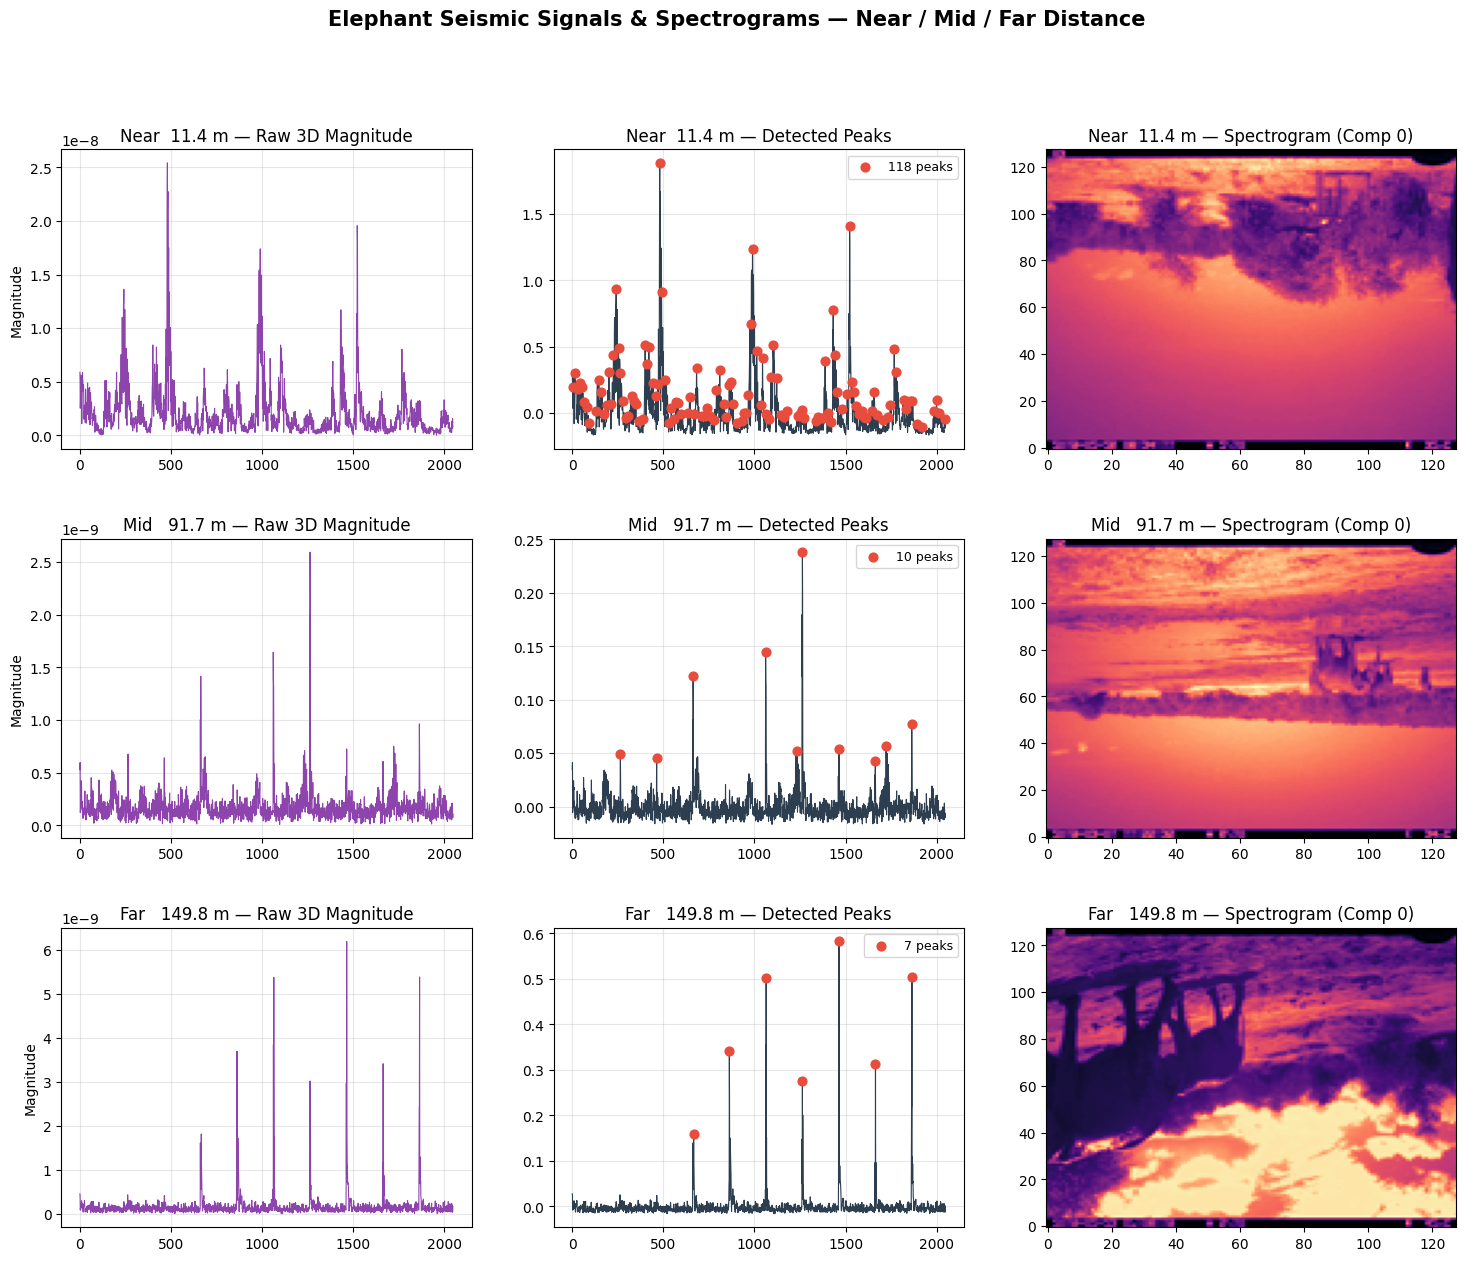

3 Elephant samples visualised with spectrograms.


In [5]:
import matplotlib.gridspec as gridspec
from scipy.signal import find_peaks

def compute_magnitude(s): return np.sqrt(s[0]**2 + s[1]**2 + s[2]**2)

dist_sorted_idx = np.argsort(selected_dist)
near_idx = dist_sorted_idx[0]
mid_idx  = dist_sorted_idx[len(dist_sorted_idx)//2]
far_idx  = dist_sorted_idx[-1]

fig = plt.figure(figsize=(18, 14))
fig.suptitle('Elephant Seismic Signals & Spectrograms — Near / Mid / Far Distance', fontsize=15, fontweight='bold')
gs = gridspec.GridSpec(3, 3, width_ratios=[1, 1, 1], hspace=0.3, wspace=0.2)

for row, (idx, label) in enumerate([
        (near_idx, f'Near  {selected_dist[near_idx]:.1f} m'),
        (mid_idx,  f'Mid   {selected_dist[mid_idx]:.1f} m'),
        (far_idx,  f'Far   {selected_dist[far_idx]:.1f} m')]):
    sig = selected_chunks[idx]
    img = selected_images[idx]
    mag = compute_magnitude(sig)
    mag_norm = (mag - mag.mean()) / (mag.std() + 1e-8)
    t = np.arange(len(mag))
    peaks, _ = find_peaks(mag_norm, prominence=0.05, distance=10)

    ax0 = fig.add_subplot(gs[row, 0])
    ax0.plot(t, mag, color='#8e44ad', linewidth=0.8)
    ax0.set_title(f'{label} — Raw 3D Magnitude')
    ax0.set_ylabel('Magnitude'); ax0.grid(True, alpha=0.3)

    ax1 = fig.add_subplot(gs[row, 1])
    ax1.plot(t, mag_norm, color='#2c3e50', linewidth=0.8)
    ax1.scatter(peaks, mag_norm[peaks], color='#e74c3c', s=40, zorder=5, label=f'{len(peaks)} peaks')
    ax1.set_title(f'{label} — Detected Peaks')
    ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3)

    ax2 = fig.add_subplot(gs[row, 2])
    ax2.imshow(img[:, :, 0], aspect='auto', cmap='magma', origin='lower')
    ax2.set_title(f'{label} — Spectrogram (Comp 0)')

plt.savefig('Elephant_visualization.png', dpi=150, bbox_inches='tight')
plt.show()
print('3 Elephant samples visualised with spectrograms.')


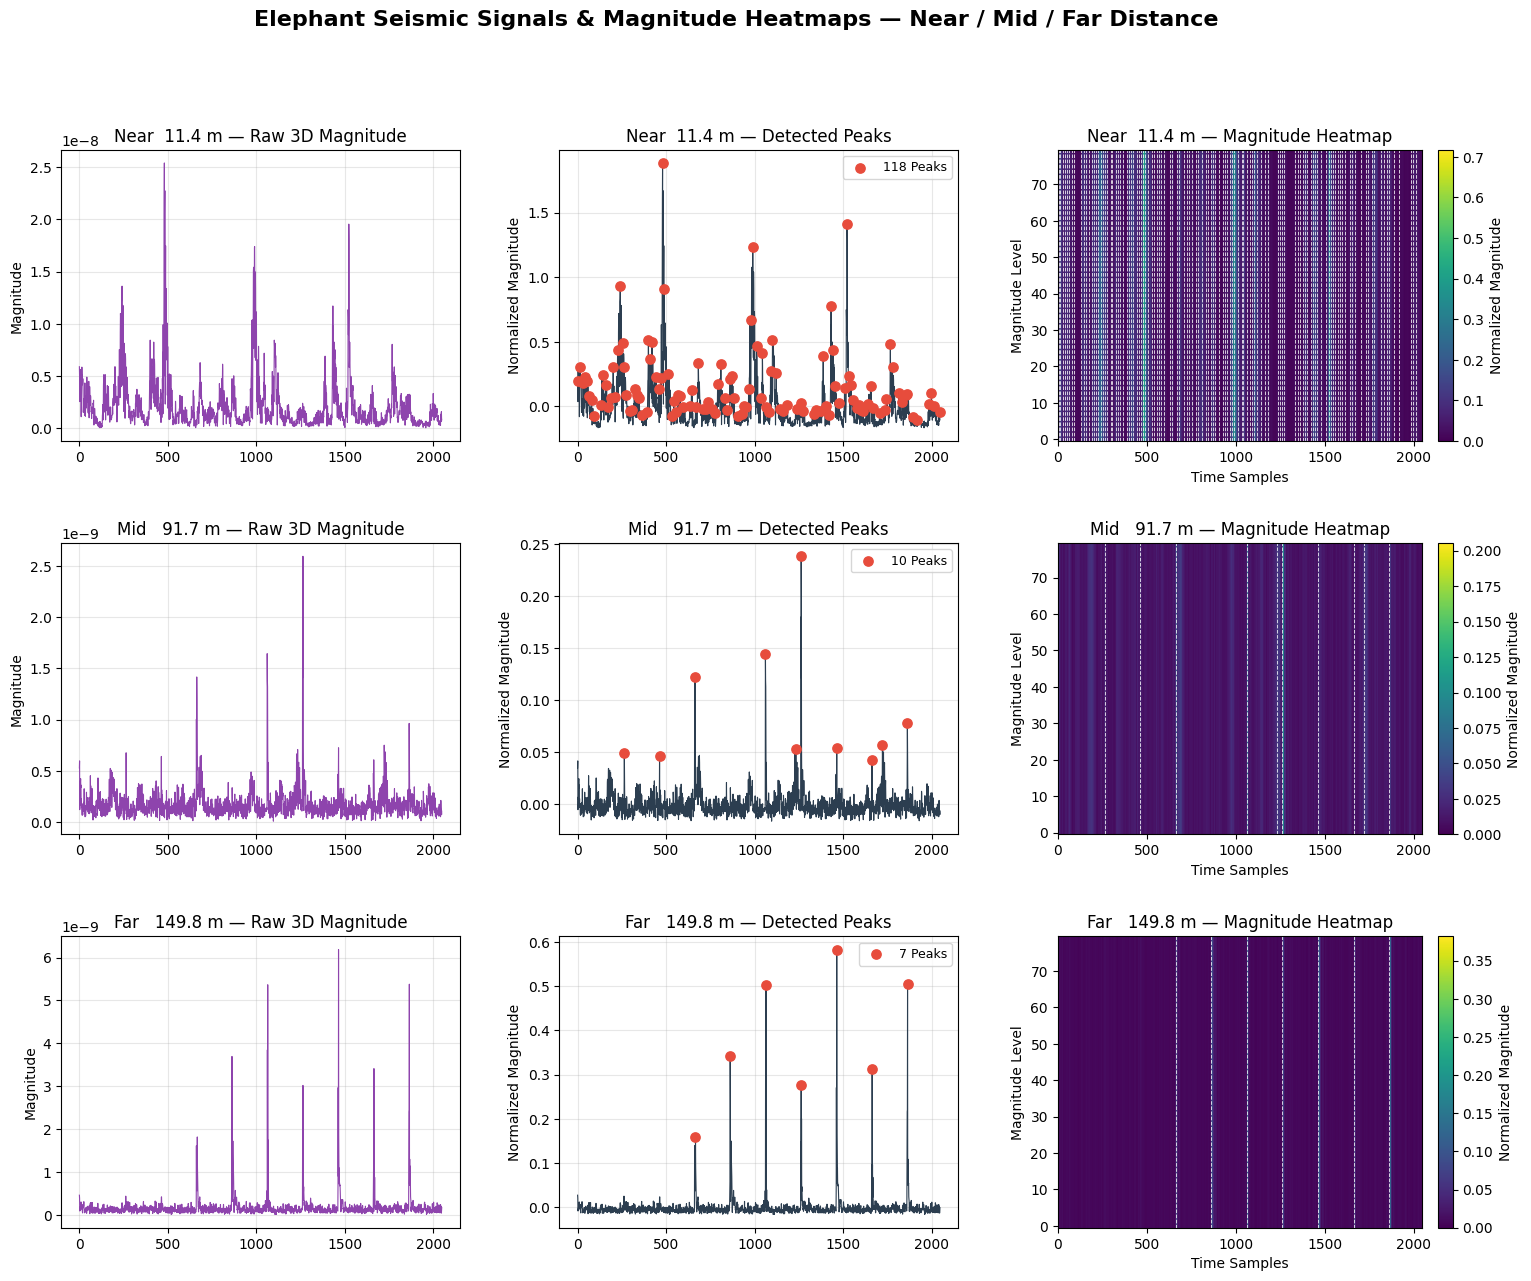

3 Elephant samples visualized with Magnitude Heatmaps.


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.signal import find_peaks

# --------------------------------------------------
# Compute Magnitude
# --------------------------------------------------
def compute_magnitude(s):
    return np.sqrt(s[0]**2 + s[1]**2 + s[2]**2)

# --------------------------------------------------
# Select Near / Mid / Far Samples
# --------------------------------------------------
dist_sorted_idx = np.argsort(selected_dist)

near_idx = dist_sorted_idx[0]
mid_idx  = dist_sorted_idx[len(dist_sorted_idx)//2]
far_idx  = dist_sorted_idx[-1]

# --------------------------------------------------
# Create Figure
# --------------------------------------------------
fig = plt.figure(figsize=(18,14))

fig.suptitle(
    "Elephant Seismic Signals & Magnitude Heatmaps — Near / Mid / Far Distance",
    fontsize=16,
    fontweight="bold"
)

gs = gridspec.GridSpec(
    3,
    3,
    width_ratios=[1,1,1],
    hspace=0.35,
    wspace=0.25
)

# --------------------------------------------------
# Loop through samples
# --------------------------------------------------
for row,(idx,label) in enumerate([

    (near_idx,f'Near  {selected_dist[near_idx]:.1f} m'),

    (mid_idx ,f'Mid   {selected_dist[mid_idx]:.1f} m'),

    (far_idx ,f'Far   {selected_dist[far_idx]:.1f} m')

]):

    sig = selected_chunks[idx]

    mag = compute_magnitude(sig)

    # Z-score normalization (same as your code)
    mag_norm = (mag-mag.mean())/(mag.std()+1e-8)

    t = np.arange(len(mag))

    peaks,_ = find_peaks(
        mag_norm,
        prominence=0.05,
        distance=10
    )

    #####################################################
    # Plot 1 : Raw Magnitude
    #####################################################

    ax0 = fig.add_subplot(gs[row,0])

    ax0.plot(
        t,
        mag,
        color="#8e44ad",
        linewidth=0.8
    )

    ax0.set_title(f"{label} — Raw 3D Magnitude")

    ax0.set_ylabel("Magnitude")

    ax0.grid(True,alpha=0.3)

    #####################################################
    # Plot 2 : Peak Detection
    #####################################################

    ax1 = fig.add_subplot(gs[row,1])

    ax1.plot(
        t,
        mag_norm,
        color="#2c3e50",
        linewidth=0.8
    )

    ax1.scatter(
        peaks,
        mag_norm[peaks],
        color="#e74c3c",
        s=45,
        zorder=5,
        label=f"{len(peaks)} Peaks"
    )

    ax1.legend(fontsize=9)

    ax1.set_title(f"{label} — Detected Peaks")

    ax1.set_ylabel("Normalized Magnitude")

    ax1.grid(True,alpha=0.3)

    #####################################################
    # Plot 3 : Magnitude Heatmap
    #####################################################

    ax2 = fig.add_subplot(gs[row,2])

    # Normalize to 0-1
    mag_heat = (mag-mag.min())/(mag.max()-mag.min()+1e-8)

    # Repeat signal vertically
    heatmap = np.tile(mag_heat,(80,1))

    im = ax2.imshow(

        heatmap,

        aspect="auto",

        cmap="viridis",

        origin="lower"

    )

    # Mark detected peaks
    for p in peaks:
        ax2.axvline(
            p,
            color="white",
            linestyle="--",
            linewidth=0.7,
            alpha=0.8
        )

    ax2.set_title(f"{label} — Magnitude Heatmap")

    ax2.set_xlabel("Time Samples")

    ax2.set_ylabel("Magnitude Level")

    cbar = plt.colorbar(
        im,
        ax=ax2,
        fraction=0.046,
        pad=0.04
    )

    cbar.set_label("Normalized Magnitude")

# --------------------------------------------------
# Save
# --------------------------------------------------

plt.savefig(
    "Elephant_Magnitude_Heatmap.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("3 Elephant samples visualized with Magnitude Heatmaps.")

---
## 🕸️ STEP 5: Graph Extraction from Raw Signal (8D Node Features)
**What I'm doing:** Converting each raw 1D vibration signal into a graph. Footstep impact peaks become **nodes** (each with an 8D feature vector). Edges connect consecutive peaks in time, plus a k-nearest-neighbors graph based on feature similarity. This step is identical to the GAT pipeline — the graph representation doesn't change; only the model that processes it changes.


In [8]:
import torch
from torch_geometric.data import Data
from sklearn.neighbors import kneighbors_graph

NUM_NODE_FEATURES = 8

def extract_raw_peaks_graph(signal_3d, label, prominence=0.05, distance=10, k_neighbors=5, window=10):
    T = signal_3d.shape[1]
    mag = np.sqrt(signal_3d[0]**2 + signal_3d[1]**2 + signal_3d[2]**2)
    mag_norm = (mag - mag.mean()) / (mag.std() + 1e-8)
    peaks, props = find_peaks(mag_norm, prominence=prominence, distance=distance)
    if len(peaks) < 2: return None

    node_feats = []
    for i, p in enumerate(peaks):
        lo, hi = max(0, p-window), min(T, p+window)
        win = mag[lo:hi]
        node_feats.append([
            float(mag[p]),
            float(signal_3d[0, p]),
            float(signal_3d[1, p]),
            float(signal_3d[2, p]),
            float(props['prominences'][i]),
            float(np.sum(win**2)) if len(win) > 0 else 0.0,
            float(np.std(win))    if len(win) > 0 else 0.0,
            float(p) / T,
        ])

    x = torch.tensor(node_feats, dtype=torch.float)
    edges, n = [], len(peaks)
    for i in range(n - 1):
        edges.append([i, i+1]); edges.append([i+1, i])
    if n > k_neighbors:
        A = kneighbors_graph(x.numpy(), n_neighbors=k_neighbors, mode='connectivity', include_self=False)
        rows, cols = A.nonzero()
        for r, c in zip(rows, cols): edges.append([r, c])
    if len(edges) == 0: return None
    edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
    y = torch.tensor([label], dtype=torch.long)
    return Data(x=x, edge_index=edge_index, y=y)

# Sanity check
g = extract_raw_peaks_graph(selected_chunks[0], 0)
if g: print(f'Elephant graph extraction OK: {g.num_nodes} nodes, {g.num_edges} edges, feature dim={g.num_node_features}')
else: print('No graph extracted for sample 0.')


Elephant graph extraction OK: 22 nodes, 152 edges, feature dim=8


---
## 🏗️ STEP 6: Build Graph Dataset from Elephant Samples
**What I'm doing:** Looping over every elephant sample, converting each to a graph, then splitting into train/test sets and wrapping them in PyTorch Geometric `DataLoader`s for mini-batch training.


In [9]:
from torch_geometric.loader import DataLoader
from sklearn.model_selection import train_test_split
from tqdm import tqdm

PROMINENCE = 0.05; DISTANCE = 10; K_NEIGHBORS = 5; WINDOW = 10
BATCH_SIZE = 64;   TEST_SIZE = 0.2

print(f'Building graph dataset from {len(selected_chunks):,} Elephant samples...')
graph_dataset, skipped = [], 0
for i in tqdm(range(len(selected_chunks))):
    g = extract_raw_peaks_graph(selected_chunks[i], 0,   # label=0, only one class
                                prominence=PROMINENCE, distance=DISTANCE,
                                k_neighbors=K_NEIGHBORS, window=WINDOW)
    if g is not None: graph_dataset.append(g)
    else: skipped += 1

print(f'Graphs: {len(graph_dataset):,},  Skipped: {skipped:,}')
print(f'All graphs belong strictly to: {TARGET_NAME} (single class)')

train_graphs, test_graphs = train_test_split(
    graph_dataset, test_size=TEST_SIZE, random_state=SEED)

train_loader = DataLoader(train_graphs, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
test_loader  = DataLoader(test_graphs,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f'Train set: {len(train_graphs):,} graphs | Test set: {len(test_graphs):,} graphs')
print('DataLoaders created ✓')


Building graph dataset from 62,493 Elephant samples...


100%|██████████| 62493/62493 [19:47<00:00, 52.64it/s] 

Graphs: 51,410,  Skipped: 11,083
All graphs belong strictly to: Elephant (single class)
Train set: 41,128 graphs | Test set: 10,282 graphs
DataLoaders created ✓


---
## 🧠 STEP 7: Graph Convolutional Autoencoder (GCN-GAE) Architecture
**What I'm doing:** Defining the model. This is the main change from the GAT version:
- Replaced both `GATConv` layers with **`GCNConv`** layers (standard spectral graph convolution — normalized neighbor-feature averaging, no learned attention weights, no `heads`/`concat` parameters).
- Kept the same encoder→latent→decoder structure so the two pipelines are directly comparable (8D input → 32D hidden → 16D latent → 8D reconstruction).
- Added `add_self_loops=True` (GCNConv default) so each node also aggregates its own features, and `improved=True` for the improved GCN normalization trick.


In [10]:
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

class ElephantGCNAutoencoder(nn.Module):
    """
    Graph Convolutional Autoencoder specialized for single-class Elephant footstep graphs.
    Encoder: compresses 8D raw footstep features into a compact 16D latent embedding using GCNConv.
    Decoder: reconstructs the original 8D raw signal features from the latent embedding.
    """
    def __init__(self, num_node_features=8, hidden_dim=32, latent_dim=16, dropout=0.2):
        super().__init__()
        self.dropout = dropout

        # ── Encoder (2-layer GCN) ──────────────────────────────────────────────
        self.enc_gcn1 = GCNConv(num_node_features, hidden_dim, improved=True)
        self.enc_gcn2 = GCNConv(hidden_dim, latent_dim, improved=True)

        # ── Decoder (MLP Feature Reconstructor) — unchanged from GAT version ──
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_node_features)
        )

    def encode(self, x, edge_index):
        h = F.relu(self.enc_gcn1(x, edge_index))
        h = F.dropout(h, p=self.dropout, training=self.training)
        z = self.enc_gcn2(h, edge_index)
        return z

    def forward(self, x, edge_index):
        # 1. Encode nodes to latent space z
        z = self.encode(x, edge_index)
        # 2. Decode back to feature space x_rec
        x_rec = self.decoder(z)
        return x_rec, z

# Clear VRAM cache before allocating model to avoid OOM from previous runs
if torch.cuda.is_available(): torch.cuda.empty_cache()
model = ElephantGCNAutoencoder(num_node_features=NUM_NODE_FEATURES).to(device)
print(model)
print(f'\nTotal trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')


ElephantGCNAutoencoder(
  (enc_gcn1): GCNConv(8, 32)
  (enc_gcn2): GCNConv(32, 16)
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=32, bias=True)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=32, out_features=8, bias=True)
  )
)

Total trainable parameters: 1,688


---
## 🔍 STEP 8: One-Class Representation Learning Setup
**What I'm doing:** Setting up the Adam optimizer, a learning-rate scheduler that reduces LR on plateau, MSE reconstruction loss, and the train/eval loop functions. This is identical logic to the GAT version — only the underlying `model` object differs.


In [11]:
import torch.optim as optim

# ── Hyperparameters for One-Class Representation Learning ───────────────────
LR           = 1e-3
WEIGHT_DECAY = 1e-4
EPOCHS       = 50
PATIENCE     = 10
MODEL_PATH   = 'PROJECT/best_elephant_gcn_gae.pth'

optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
criterion = nn.MSELoss()   # Reconstruction loss between real features and decoded features

def train_one_epoch(model, loader, optimizer):
    model.train(); total_loss = 0.0
    for data in loader:
        data = data.to(device); optimizer.zero_grad()
        x_rec, _ = model(data.x, data.edge_index)
        loss = criterion(x_rec, data.x)   # Learn to reconstruct Elephant footstep features perfectly
        loss.backward(); optimizer.step()
        total_loss += loss.item() * data.num_graphs
    return total_loss / len(loader.dataset)

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); total_loss = 0.0
    for data in loader:
        data = data.to(device)
        x_rec, _ = model(data.x, data.edge_index)
        loss = criterion(x_rec, data.x)
        total_loss += loss.item() * data.num_graphs
    return total_loss / len(loader.dataset)

print('One-Class Graph Convolutional Autoencoder setup complete ✓')


One-Class Graph Convolutional Autoencoder setup complete ✓


---
## 🚂 STEP 9: Train Elephant Graph Convolutional Autoencoder
**What I'm doing:** Running the training loop for up to 50 epochs, tracking train/test MSE, saving the best-performing checkpoint, and stopping early if test loss doesn't improve for 10 consecutive epochs.


In [12]:
train_losses, test_losses = [], []
best_test_loss = float('inf'); patience_cnt = 0

print(f'Training Elephant Graph Convolutional Autoencoder for {EPOCHS} epochs...')
for epoch in range(1, EPOCHS + 1):
    tr_loss = train_one_epoch(model, train_loader, optimizer)
    te_loss = evaluate(model, test_loader)
    scheduler.step(te_loss)
    train_losses.append(tr_loss); test_losses.append(te_loss)

    if te_loss < best_test_loss:
        best_test_loss = te_loss
        torch.save(model.state_dict(), MODEL_PATH)
        patience_cnt = 0
    else:
        patience_cnt += 1

    if epoch % 5 == 0 or epoch == 1:
        print(f'Epoch {epoch:03d} | Train MSE Loss: {tr_loss:.6f} | Test MSE Loss: {te_loss:.6f}')

    if patience_cnt >= PATIENCE:
        print(f'Early stopping triggered at epoch {epoch}'); break

print(f'\n🏆 Best Test Reconstruction Loss: {best_test_loss:.6f}')
print(f'Model saved to: {MODEL_PATH}')


Training Elephant Graph Convolutional Autoencoder for 50 epochs...
Epoch 001 | Train MSE Loss: 0.024875 | Test MSE Loss: 0.003774
Epoch 005 | Train MSE Loss: 0.003780 | Test MSE Loss: 0.002835
Epoch 010 | Train MSE Loss: 0.003186 | Test MSE Loss: 0.002332
Epoch 015 | Train MSE Loss: 0.003062 | Test MSE Loss: 0.002549
Epoch 020 | Train MSE Loss: 0.003004 | Test MSE Loss: 0.002138
Epoch 025 | Train MSE Loss: 0.002968 | Test MSE Loss: 0.002143
Epoch 030 | Train MSE Loss: 0.002945 | Test MSE Loss: 0.002127
Epoch 035 | Train MSE Loss: 0.002951 | Test MSE Loss: 0.002125
Epoch 040 | Train MSE Loss: 0.002951 | Test MSE Loss: 0.002087
Epoch 045 | Train MSE Loss: 0.002933 | Test MSE Loss: 0.002142
Epoch 050 | Train MSE Loss: 0.002933 | Test MSE Loss: 0.002137

🏆 Best Test Reconstruction Loss: 0.002084
Model saved to: PROJECT/best_elephant_gcn_gae.pth


---
## 📈 STEP 10: Training Curves (Reconstruction Loss)
**What I'm doing:** Plotting train vs. test MSE across epochs to visually confirm the GCN autoencoder is converging and not overfitting.


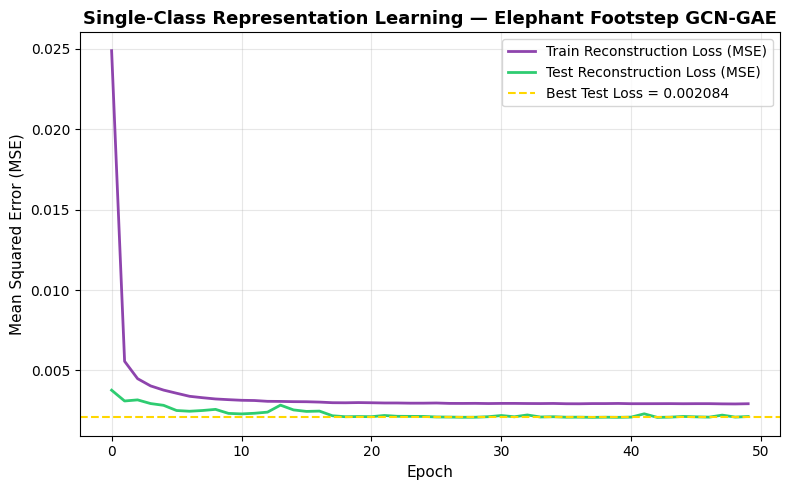

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(train_losses, color='#8e44ad', label='Train Reconstruction Loss (MSE)', linewidth=2)
ax.plot(test_losses,  color='#2ecc71', label='Test Reconstruction Loss (MSE)',  linewidth=2)
ax.axhline(best_test_loss, color='gold', linestyle='--', label=f'Best Test Loss = {best_test_loss:.6f}')
ax.set_xlabel('Epoch', fontsize=11); ax.set_ylabel('Mean Squared Error (MSE)', fontsize=11)
ax.set_title('Single-Class Representation Learning — Elephant Footstep GCN-GAE', fontsize=13, fontweight='bold')
ax.legend(fontsize=10); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('elephant_gcn_gae_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 🚨 STEP 11: Real-Time Anomaly Scoring Demonstration
**What I'm doing:** Computing reconstruction error on real held-out elephant graphs ("normal" scores), then simulating anomalous graphs by injecting random noise into the node features, and comparing the two error distributions. A large separation ratio confirms the GCN autoencoder can distinguish elephants from unknown disturbances.


Single-Species Anomaly Scoring (Reconstruction Error) — GCN
Normal Elephant Footsteps — Mean Error : 0.002226 (std: 0.005574)
Anomalous Ground Vibrations — Mean Error : 6.037249 (std: 0.659775)
Separation Ratio                         : 2712.3x higher error for anomalies


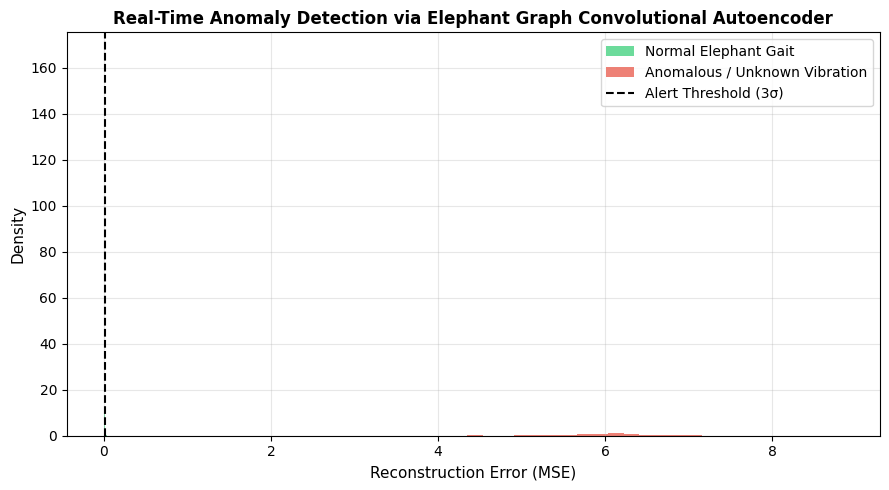

In [14]:
# ── Demonstrate Real-Time Anomaly Detection ─────────────────────────────────
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()

@torch.no_grad()
def get_graph_anomaly_scores(model, loader):
    scores = []
    for data in loader:
        data = data.to(device)
        x_rec, _ = model(data.x, data.edge_index)
        error_per_node = ((x_rec - data.x) ** 2).mean(dim=1)
        for g_idx in range(data.num_graphs):
            mask = (data.batch == g_idx)
            graph_error = error_per_node[mask].mean().item()
            scores.append(graph_error)
    return np.array(scores)

normal_scores = get_graph_anomaly_scores(model, test_loader)

# Simulate anomalous footstep graphs (e.g. random high-frequency ground noise / impacts)
anomalous_graphs = []
for g in test_graphs[:200]:
    g_noisy = g.clone()
    g_noisy.x = g.x + torch.randn_like(g.x) * 2.5   # Distort footstep features
    anomalous_graphs.append(g_noisy)
anom_loader = DataLoader(anomalous_graphs, batch_size=64, shuffle=False)
anom_scores = get_graph_anomaly_scores(model, anom_loader)

print('=' * 60)
print('Single-Species Anomaly Scoring (Reconstruction Error) — GCN')
print('=' * 60)
print(f'Normal Elephant Footsteps — Mean Error : {normal_scores.mean():.6f} (std: {normal_scores.std():.6f})')
print(f'Anomalous Ground Vibrations — Mean Error : {anom_scores.mean():.6f} (std: {anom_scores.std():.6f})')
print(f'Separation Ratio                         : {anom_scores.mean() / (normal_scores.mean() + 1e-8):.1f}x higher error for anomalies')

plt.figure(figsize=(9, 5))
plt.hist(normal_scores, bins=30, alpha=0.7, color='#2ecc71', label='Normal Elephant Gait', density=True)
plt.hist(anom_scores,   bins=30, alpha=0.7, color='#e74c3c', label='Anomalous / Unknown Vibration', density=True)
plt.axvline(normal_scores.mean() + 3*normal_scores.std(), color='black', linestyle='--', label='Alert Threshold (3σ)')
plt.xlabel('Reconstruction Error (MSE)', fontsize=11); plt.ylabel('Density', fontsize=11)
plt.title('Real-Time Anomaly Detection via Elephant Graph Convolutional Autoencoder', fontsize=12, fontweight='bold')
plt.legend(fontsize=10); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('elephant_gcn_anomaly_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 📦 STEP 12: Edge-Deployable INT8 Quantized Model
**What I'm doing:** Loading the best checkpoint on CPU and applying dynamic INT8 quantization to the `nn.Linear` layers (the decoder + any linear ops), shrinking the model for deployment on low-power field microcontrollers/IoT sensors.


In [15]:
model.load_state_dict(torch.load(MODEL_PATH, map_location='cpu'))
model_cpu = model.to('cpu'); model_cpu.eval()

# Quantize linear layers in encoder/decoder to INT8
tiny_model = torch.quantization.quantize_dynamic(model_cpu, {nn.Linear}, dtype=torch.qint8)
TINY_PATH  = 'tiny_elephant_gcn_gae_int8.pth'
torch.save(tiny_model.state_dict(), TINY_PATH)

fp32_size = os.path.getsize(MODEL_PATH) / 1024
int8_size = os.path.getsize(TINY_PATH)  / 1024
print('Edge-Deployable One-Class Anomaly Detector (INT8) — GCN version')
print(f'  FP32 Model Size : {fp32_size:.1f} KB')
print(f'  INT8 Model Size : {int8_size:.1f} KB  ({fp32_size/int8_size:.1f}x smaller)')
print(f'  Saved to        : {TINY_PATH}')
print('\n💡 Edge Deployment Workflow on IoT / Sensor Microcontroller:')
print('   1. Continuously record 3D ground vibration (X,Y,Z)')
print('   2. When magnitude exceeds threshold, extract footstep peaks (O(N) math)')
print('   3. Pass graph through tiny INT8 GCN Autoencoder')
print('   4. If MSE < Threshold -> Log "Elephant Detected"')
print('   5. If MSE > Threshold -> Ignore / Alert "Unknown Disturbance"')


Edge-Deployable One-Class Anomaly Detector (INT8) — GCN version
  FP32 Model Size : 12.3 KB
  INT8 Model Size : 11.4 KB  (1.1x smaller)
  Saved to        : tiny_elephant_gcn_gae_int8.pth

💡 Edge Deployment Workflow on IoT / Sensor Microcontroller:
   1. Continuously record 3D ground vibration (X,Y,Z)
   2. When magnitude exceeds threshold, extract footstep peaks (O(N) math)
   3. Pass graph through tiny INT8 GCN Autoencoder
   4. If MSE < Threshold -> Log "Elephant Detected"
   5. If MSE > Threshold -> Ignore / Alert "Unknown Disturbance"


/tmp/ipykernel_2141429/4144121267.py:5: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  tiny_model = torch.quantization.quantize_dynamic(model_cpu, {nn.Linear}, dtype=torch.qint8)


---
## 📝 STEP 13: Paper Summary Table & Scientific Highlights
**What I'm doing:** Printing a final summary of the architecture, dataset, and results — useful for a report or paper, and lets me quickly compare against the GAT version.


In [16]:
print('=' * 70)
print('PAPER SUMMARY — Single-Species Representation Learning (Elephant, GCN)')
print('=' * 70)
print(f'  Task Type         : One-Class Graph Representation Learning & Anomaly Detection')
print(f'  Target Species    : Elephant (Class 1) — 62,493 raw seismic recordings')
print(f'  Input Representation : Raw 3D Seismic Signal (√(X²+Y²+Z²) envelope) — NO Spectrograms')
print(f'  Graph Nodes       : Detected footstep impact peaks (8D raw physical features)')
print(f'  Graph Edges       : Sequential temporal chain + kNN feature similarity')
print(f'  Model Architecture: Graph Convolutional Autoencoder (GCN-GAE)')
print(f'  Encoder           : 2-Layer GCNConv (compressing 8D -> 16D latent embedding)')
print(f'  Decoder           : MLP Reconstructor (rebuilding 8D footstep physical features)')
print(f'  Total Params      : {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')
print(f'  Best Test MSE     : {best_test_loss:.6f}')
print(f'  INT8 Model Size   : {int8_size:.1f} KB (Edge/IoT Microcontroller Ready)')
print(f'  Key Scientific Value : Eliminates need for negative/background training data.')
print(f'                         Enables robust deployment where only one endangered animal is monitored.')
print(f'  Note vs GAT version  : GCN uses fixed normalized-adjacency aggregation (no attention),')
print(f'                         giving fewer parameters and faster training at a possible small')
print(f'                         cost to expressive power on irregular graph structures.')
print('=' * 70)


PAPER SUMMARY — Single-Species Representation Learning (Elephant, GCN)
  Task Type         : One-Class Graph Representation Learning & Anomaly Detection
  Target Species    : Elephant (Class 1) — 62,493 raw seismic recordings
  Input Representation : Raw 3D Seismic Signal (√(X²+Y²+Z²) envelope) — NO Spectrograms
  Graph Nodes       : Detected footstep impact peaks (8D raw physical features)
  Graph Edges       : Sequential temporal chain + kNN feature similarity
  Model Architecture: Graph Convolutional Autoencoder (GCN-GAE)
  Encoder           : 2-Layer GCNConv (compressing 8D -> 16D latent embedding)
  Decoder           : MLP Reconstructor (rebuilding 8D footstep physical features)
  Total Params      : 1,688
  Best Test MSE     : 0.002084
  INT8 Model Size   : 11.4 KB (Edge/IoT Microcontroller Ready)
  Key Scientific Value : Eliminates need for negative/background training data.
                         Enables robust deployment where only one endangered animal is monitored.
  Note 